# Feature importance

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/biprateep/lazy-tfm/blob/tutorials/feature_importance.ipynb)
[![View on GitHub](https://img.shields.io/badge/View%20on-GitHub-181717?logo=github)](https://github.com/biprateep/lazy-tfm/blob/tutorials/feature_importance.ipynb)

A tabular foundation model has no coefficients to read and no tree splits to
count, so the question of which features a prediction depends on has to be
asked from the outside, by changing the inputs and watching the outputs.
Since every model in `lazy` follows the scikit-learn API, the standard
model-agnostic tools work on it directly. In this tutorial, we use two of
them on a small engineering dataset: scikit-learn's permutation importance,
which measures how much a score worsens when a feature is shuffled, and SHAP
values, which split each prediction into the contributions of its features.
Because the models predict a full distribution, we can ask both questions
not only of the predicted value but also of its uncertainty.

## Setup

On Google Colab, the cell below installs the package with the TabICL backend
and the [`shap`](https://shap.readthedocs.io) package. Elsewhere, install
them first with `pip install 'lazy-tfm[tabicl]' shap`.

In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install -q 'lazy-tfm[tabicl]' shap
    pass

In [2]:
import matplotlib.pyplot as plt  # Plotting
import numpy as np  # Arrays
import pandas as pd  # Tables
import shap  # SHAP values
from sklearn import inspection  # Permutation importance
from sklearn import model_selection  # Splits

import lazy  # The topic of this tutorial
from lazy import datasets
from lazy import metrics
from lazy import plotting

SEED = 299792458  # One seed for the split, the model and the explainers

plotting.use_style()
plt.rcParams["figure.dpi"] = 110  # Readable in a notebook

## The data and the model

The concrete dataset (see
[Demo datasets](https://lazy-tfm.readthedocs.io/en/latest/guide/datasets.html))
gives the compressive strength, in MPa, of 1,030 concrete samples from the
amounts of their seven ingredients, in kg per cubic meter of concrete, and
their age in days. It is a convenient test of feature importance, since the
physics is well known: concrete gains strength as it cures, with more
cement, and with less water for the same cement. We hold out 20% of the rows
for testing.

In [3]:
data = datasets.load_dataset("concrete")
X_train, X_test, y_train, y_test = model_selection.train_test_split(
    data.X, data.y, test_size=0.2, random_state=SEED
)
print(f"{len(X_train):,} context rows, {len(X_test):,} test rows")
X_train.head()

824 context rows, 206 test rows


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age
959,312.9,160.5,0.0,177.6,9.60,916.6,759.5,28
100,425.0,106.3,0.0,153.5,16.50,852.1,887.1,7
403,356.0,119.0,0.0,160.0,9.03,1061.0,657.0,28
99,469.0,117.2,0.0,137.8,32.20,852.1,840.5,7
401,475.0,0.0,0.0,162.0,9.50,1044.0,662.0,28


We use TabICL, which is small and quick on any hardware, since both methods
below predict the test set many times over. Any other model of
`lazy.LazyModel` can be swapped in without changing the rest of the code. As
a reminder of how well the model does before we ask why, we report its CRPS
(in MPa, lower is better) and the fraction of test rows inside their central
68% interval.

In [4]:
model = lazy.LazyModel("tabicl", random_state=SEED, progress=False)
model.fit(X_train, y_train)

low, high = model.predict_interval(X_test, coverage=0.68).T
coverage = np.mean((y_test >= low) & (y_test <= high))
scores = model.evaluate(X_test, y_test)
print(f"CRPS: {scores['crps'].iloc[0]:.2f} MPa")
print(f"68% interval coverage: {coverage:.0%}")
print(f"Median width of the 68% interval: {np.median(high - low):.1f} MPa")

CRPS: 1.83 MPa
68% interval coverage: 65%
Median width of the 68% interval: 3.8 MPa


## Permutation importance

Permutation importance shuffles one feature across the test rows, which
breaks its relation to the target while keeping its distribution, and
measures how much a score drops as a result. A feature the model does not
use loses nothing when shuffled, and the more the model relies on a
feature, the larger the drop. The shuffle is repeated a few times to give
a spread. Since the model is a scikit-learn estimator,
`sklearn.inspection.permutation_importance` takes it as it is.

The importance depends on the score we choose. For the predicted value, we
use the mean absolute error of the predicted median, and for the full
distribution, the CRPS. Neither is one of scikit-learn's built-in scorers
(its `"neg_mean_absolute_error"` would score `predict`, which gives the
mode), so we write each as a scorer: a function of the fitted model and the
data that returns a number where higher is better. Both are in MPa, so the
two importances can be compared directly. We compute them on the test rows
rather than the context rows, since an in-context model has seen the context
rows and would recall their targets, which makes every feature look less
important than it is.

In [5]:
GRID = lazy.Grid.linear(0, 100, 500)  # Strength in MPa, for the CRPS


def neg_mae(estimator: lazy.LazyModel, X: pd.DataFrame, y: np.ndarray) -> float:
    """Minus the mean absolute error of the predicted medians."""
    median = estimator.predict_quantiles(X, [0.5])[:, 0]
    return -float(np.mean(np.abs(y - median)))


def neg_crps(
    estimator: lazy.LazyModel, X: pd.DataFrame, y: np.ndarray
) -> float:
    """Minus the CRPS of the predicted distributions."""
    return -metrics.crps(y, GRID, estimator.predict_proba(X, GRID))


importances = {}
for label, scoring in [
    ("Median (MAE)", neg_mae),
    ("Distribution (CRPS)", neg_crps),
]:
    result = inspection.permutation_importance(
        model,
        X_test,
        y_test,
        scoring=scoring,
        n_repeats=10,
        random_state=SEED,
    )
    importances[label] = pd.DataFrame(
        {"mean": result.importances_mean, "std": result.importances_std},
        index=X_test.columns,
    )

The figure shows, for each feature, how much the score worsens when that
feature is shuffled, with the error bars giving the spread over the ten
shuffles.

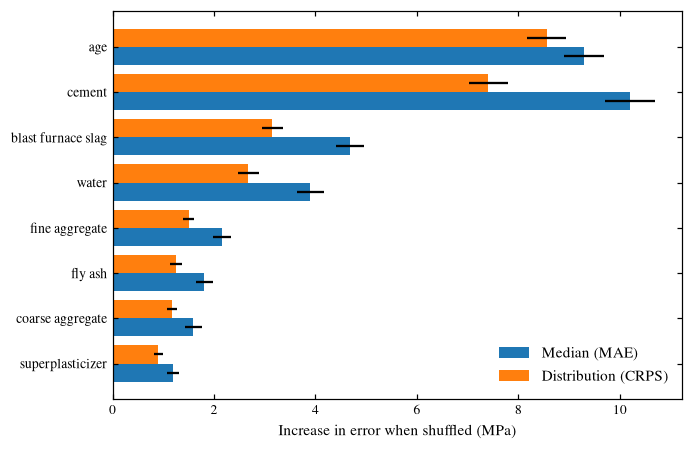

In [6]:
order = importances["Distribution (CRPS)"]["mean"].sort_values().index
positions = np.arange(len(order))
fig, ax = plt.subplots(figsize=(6.4, 4.2))
for offset, (label, table) in zip([-0.2, 0.2], importances.items()):
    ax.barh(
        positions + offset,
        table.loc[order, "mean"],
        height=0.4,
        xerr=table.loc[order, "std"],
        label=label,
    )
ax.set_yticks(positions, [name.replace("_", " ") for name in order])
ax.set_xlabel("Increase in error when shuffled (MPa)")
ax.legend(loc="lower right")
fig.tight_layout()

Age and cement dominate, followed by blast furnace slag and water, which
matches the physics of concrete: strength grows with curing time and with
the cement and slag that bind the mix, and falls with excess water. The
median and the full distribution rank the features in nearly the same
order, with the smaller differences in MPa for the distribution.

Permutation importance has a known weakness with correlated features: when
two features carry the same information, shuffling either one leaves the
other to stand in for it, and both look less important than they are. The
ingredients of concrete are correlated (for instance, more fly ash tends to
come with less cement), so these numbers rank the features rather than
measure their effects.

## SHAP values

SHAP values (from SHapley Additive exPlanations; [Lundberg & Lee
2017](https://arxiv.org/abs/1705.07874)) split a single prediction into one
contribution per feature, which add up to the difference between that
prediction and the average prediction over a set of reference rows (also
called the background). They come from the Shapley values of cooperative
game theory, which share a payout among players in proportion to what each
adds to every possible coalition of the others. The `shap` package works
with any function of the features, so we pass it a function that returns,
for each row, two numbers taken from the predicted distribution: its median
and the width of its central 68% interval. One explainer then gives the
contributions to both the predicted value and its uncertainty.

The reference rows matter for an in-context model. If we drew them from the
context, the model would recognize them and predict their targets with very
narrow intervals, so the average width would describe memorized rows rather
than new ones. We therefore take the reference rows from the held-out set
and explain the other held-out rows. We use the permutation algorithm of
`shap`, which needs only predictions, and give it enough evaluations for ten
random orders of the features per row.

In [7]:
def median_and_width(X: pd.DataFrame) -> np.ndarray:
    """Each row's predicted median and 68% interval width, shape (n, 2)."""
    low, median, high = model.predict_quantiles(X, [0.16, 0.5, 0.84]).T
    return np.column_stack([median, high - low])


X_reference, X_explain = model_selection.train_test_split(
    X_test, train_size=30, random_state=SEED
)
explainer = shap.PermutationExplainer(median_and_width, X_reference, seed=SEED)
explanation = explainer(
    X_explain, max_evals=10 * 2 * X_test.shape[1] + 1, silent=True
)
explanation.feature_names = [name.replace("_", " ") for name in X_test.columns]
median_shap = explanation[:, :, 0]
width_shap = explanation[:, :, 1]
print(
    f"Average over the reference rows: median {median_shap.base_values[0]:.1f}"
    f" MPa, 68% width {width_shap.base_values[0]:.1f} MPa"
)

Average over the reference rows: median 36.7 MPa, 68% width 5.3 MPa


The beeswarm plot below shows every explained row as one point per feature:
its position is the feature's contribution to that row's predicted median,
and its color is the feature's value in that row, from low (blue) to high
(red). The features are sorted by their mean absolute contribution.

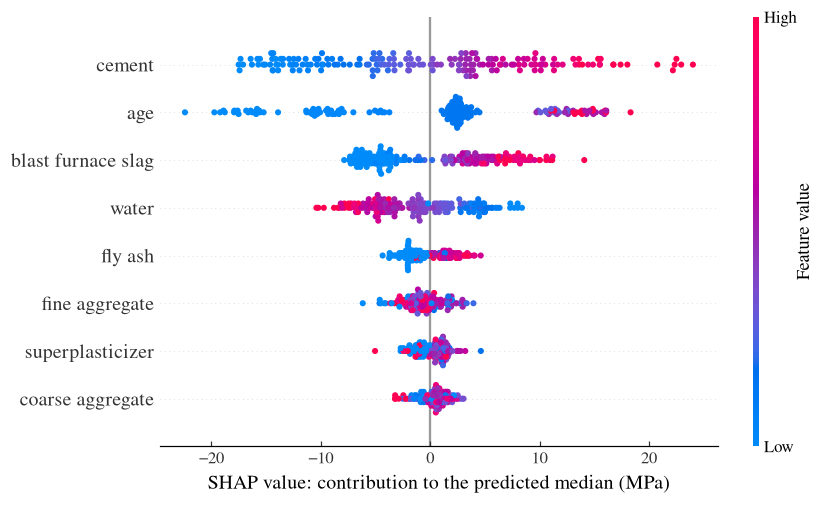

In [8]:
shap.plots.beeswarm(median_shap, show=False)
plt.xlabel("SHAP value: contribution to the predicted median (MPa)")
plt.tight_layout()

The SHAP values agree with permutation importance on which features matter,
and add the direction of each effect: old samples and samples rich in
cement are predicted stronger, and samples with much water weaker, as
expected. They also show that the effect of age is strongly nonlinear: the
youngest samples are predicted weaker by up to about 20 MPa and the oldest
stronger by 10 to 15 MPa, while most samples, tested at the common curing
age of 28 days, sit close to zero.

The same plot for the width of the 68% interval shows which features make
the model more or less certain of a given row.

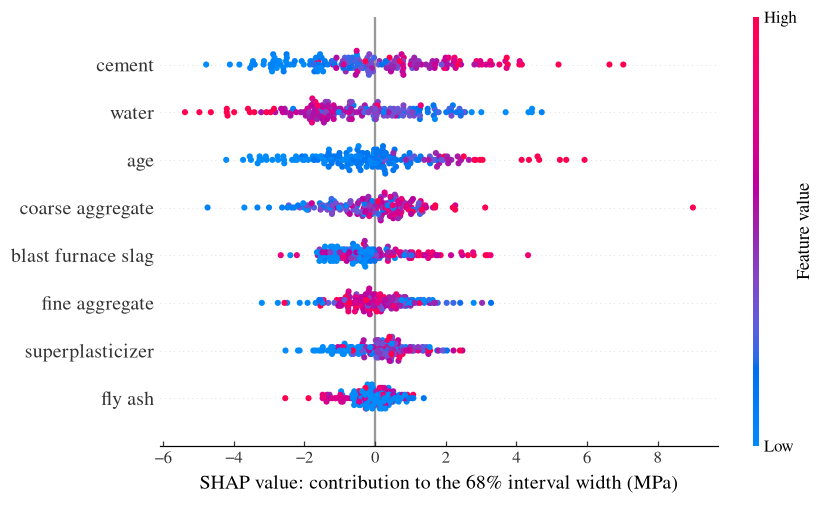

In [9]:
shap.plots.beeswarm(width_shap, show=False)
plt.xlabel("SHAP value: contribution to the 68% interval width (MPa)")
plt.tight_layout()

The intervals are wider for the samples with more cement, less water and a
greater age, which are also those predicted strongest, so the model's
uncertainty grows with the strength it predicts. The uncertainty is also
driven by a different mix of features than the prediction itself, which we
can see by comparing the mean absolute contribution of each feature to the
two quantities: water and coarse aggregate weigh more on the width than on
the median, and blast furnace slag less.

In [10]:
mean_contribution = pd.DataFrame(
    {
        "Median": np.abs(median_shap.values).mean(axis=0),
        "68% width": np.abs(width_shap.values).mean(axis=0),
    },
    index=explanation.feature_names,
).sort_values("Median", ascending=False)
mean_contribution.round(2)

,Median,68% width
cement,8.73,1.70
age,8.08,1.36
blast furnace slag,5.17,0.93
water,3.88,1.53
fly ash,1.76,0.46
fine aggregate,1.43,0.75
superplasticizer,1.12,0.71
coarse aggregate,1.00,0.96


## Summary

Since `lazy`'s models are scikit-learn estimators, permutation importance
takes them as they are, and SHAP takes any of their outputs as a function
of the features. The ranking of the features agrees between the two methods
and with the physics of concrete, and the full distribution lets us ask
which features drive the uncertainty of a prediction as well as its value.
Two things are specific to in-context models: importances and reference rows
should come from rows outside the context, which the model would otherwise
recall, and every method here predicts the same rows many times, which a
small model such as TabICL keeps fast. With a larger model, fewer explained
rows or fewer SHAP evaluations keep the cost down.